In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from pathlib import Path

In [43]:
import pickle
df = pd.read_csv(r'E:\Bank_Transaction_Categorization_Tool_repos\data\spending_patterns_detailed.csv')  # Ensure your CSV has 'Date' and 'Close' columns 

df.head()

print(df[df['Price Per Unit']>10000])



     Customer ID  Category Item  Quantity  Price Per Unit  Total Spent  \
16     CUST_0065  Shopping  Car         4        59807.04    239228.17   
36     CUST_0073  Shopping  Car         1        48275.65     48275.65   
63     CUST_0154  Shopping  Car         4        53291.61    213166.43   
82     CUST_0112  Shopping  Car         2        37755.26     75510.53   
130    CUST_0002  Shopping  Car         1        66772.13     66772.13   
...          ...       ...  ...       ...             ...          ...   
9860   CUST_0104  Shopping  Car         2        45640.76     91281.53   
9882   CUST_0037  Shopping  Car         3        72970.50    218911.50   
9895   CUST_0080  Shopping  Car         3        27587.08     82761.25   
9909   CUST_0163  Shopping  Car         1        62682.74     62682.74   
9954   CUST_0147  Shopping  Car         1        52249.94     52249.94   

      Payment Method    Location Transaction Date  
16    Digital Wallet    In-store       2023-11-27  
36     

In [18]:
import os

save_path = ("E:\\Bank_Transaction_Categorization_Tool_repos\\reports\\plots\\abc.txt")
filename = os.path.basename(save_path)

name_only, extension = os.path.splitext(filename)

print(name_only)
print(extension)


abc
.txt


In [48]:
a = df[['Range', 'Item', 'Location']].agg(' '.join, axis=1)

print(a)

0                       Low Milk Mobile App
1       Medium Dinner with Friends In-store
2                 Low Water Bill Mobile App
3                   Low Yoga Class In-store
4                   Medium Flowers In-store
                       ...                 
9995                  Low Water Bill Online
9996                    Low Snacks In-store
9997            Medium Electronics In-store
9998           Medium Car Repair Mobile App
9999                Low Gas Bill Mobile App
Length: 10000, dtype: str


In [47]:
df = pd.read_csv(r'E:\Bank_Transaction_Categorization_Tool_repos\data\spending_patterns_detailed.csv')  # Ensure your CSV has 'Date' and 'Close' columns 
bins = [0, 100, 1000, 5000, 10000, float('inf')]
labels = ['Low', 'Medium', 'High', 'Very High', 'Highest']

# Apply custom cut
df['Range'] = pd.cut(df['Total Spent'], bins=bins, labels=labels, right=True)

df['Item_join'] = df['Item'] + " " + df['Location'] + " " + str(df['Range'])

df.head()

df.to_csv("E:\\Bank_Transaction_Categorization_Tool_repos\\data\\abc.csv", index=False)

In [32]:
df['Range'].isna()

0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Name: Range, Length: 10000, dtype: bool

In [45]:
df = pd.read_csv(r'E:\Bank_Transaction_Categorization_Tool_repos\data\spending_patterns_detailed.csv')  # Ensure your CSV has 'Date' and 'Close' columns 
bins = [0, 100, 1000, 10000, float('inf')]
labels = ['Low', 'Medium', 'High', 'Very High']

    # Apply custom cut
df['Range'] = pd.cut(df['Total Spent'], bins=bins, labels=labels, right=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Customer ID       10000 non-null  str     
 1   Category          10000 non-null  str     
 2   Item              10000 non-null  str     
 3   Quantity          10000 non-null  int64   
 4   Price Per Unit    10000 non-null  float64 
 5   Total Spent       10000 non-null  float64 
 6   Payment Method    10000 non-null  str     
 7   Location          10000 non-null  str     
 8   Transaction Date  10000 non-null  str     
 9   Range             10000 non-null  category
dtypes: category(1), float64(2), int64(1), str(6)
memory usage: 1.2 MB


In [51]:
df['Payment category'] = df['Payment Method'].replace({'Credit Card': 'Card', 'Debit Card': 'Card'})

df.head()


,Customer ID,Category,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Range,Item_join,Payment category
0,CUST_0159,Groceries,Milk,1,1.28,1.28,Debit Card,Mobile App,2024-11-13,Low,Milk Mobile App 0 Low\n1 Medium...,Card
1,CUST_0017,Friend Activities,Dinner with Friends,2,74.69,149.39,Debit Card,In-store,2023-05-04,Medium,Dinner with Friends In-store 0 Low\n1...,Card
2,CUST_0094,Housing and Utilities,Water Bill,1,76.06,76.06,Digital Wallet,Mobile App,2023-12-16,Low,Water Bill Mobile App 0 Low\n1 ...,Digital Wallet
3,CUST_0162,Fitness,Yoga Class,5,11.24,56.18,Cash,In-store,2024-01-28,Low,Yoga Class In-store 0 Low\n1 Me...,Cash
4,CUST_0129,Gifts,Flowers,3,43.71,131.12,Debit Card,In-store,2023-07-28,Medium,Flowers In-store 0 Low\n1 Mediu...,Card


In [54]:
df = df[df['Payment Method' ]!= 'Cash']

In [ ]:
import numpy as np
import pandas as pd
bins = [(i*50) for i in range(0, (19))] + 



 #2. Automatically generate string labels from '1' up to the total number of bins
labels = [str(i) for i in range(1, len(bins))]
print(bins)

[0, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600, 650, 700, 750, 800, 850, 900, 'float(inf)']


In [81]:
import random
name_raw_len = np.random.normal(loc=5.5, scale=2.0, size=1000)
name_discrete_samples = np.clip(np.round(name_raw_len), 3, 10).astype(int)

name_v = np.random.normal(loc=11.5, scale=3.5, size=1000).astype(int)
name_v = np.clip(name_v, 1, 22)
name_samples_v = np.clip(np.round(name_v), 1, 22).astype(int)

#print(discrete_samples)
vowel = ['a', 'e', 'i', 'o', 'u' ]

cons = ['s', 'z', 'sh' , 'a', 'e', 'i'  , 'l', 'r',  'd', 't', 'k', 'p', 'b', 'g' , 'n', 'm' ,    'y', 'w', 'o', 'u',   'f', 'v', 'h']
count=0

for i in name_discrete_samples:
    name = []
    if count > 999:
        break
    else:
        for j in range(i):
            count = count + 1 
            #print(i,j)
            if (j+1)%2 == 0:
                name.append(vowel[random.randint(1, 5)-1])
            else:
                if j==0:   
                    name.append(cons[name_samples_v[count]].upper())
                else:
                    name.append(cons[name_samples_v[count]])
    name = "".join(name) 
    print(name)
    

Dokukup
Rakuto
Giiieuk
Pagetag
Mugibit
Pumudo
Rego
Rubapan
Gagak
Bor
Tabai
Mimagoko
Gota
Iiyo
Noiodab
Noi
Buperu
Eagot
Pemate
Lileru
Uakogana
Kigoku
Lukot
Liy
Geti
Ranotut
Motu
Oigobe
Eubor
Rip
Bekek
Boshageko
Binipubel
Wogugi
Nam
Piee
Tokit
Kayo
Mepugi
Regitabow
Kogera
Gushap
Mug
Pudutun
Lag
Yudigaoe
Tii
Ponododu
Bobepe
Maparuton
Neiuzako
Pap
Yup
Gutom
Gatel
Mul
Gopebobep
Guregapiyo
Pit
Oamu
Kenit
Nogeper
Maku
Kokipanino
Golayop
Gagiri
Gatupagog
Numowa
Toshepu
Tigeku
Rekorego
Rug
Gobipa
Lenag
Matagom
Iin
Mopu
Gigomik
Kopapu
Megagel
Pebik
Kebu
Lonote
Aud
Wal
Bun
Geb
Rom
Kepal
Megibubod
Tomo
Bereg
Mib
Neme
Gashun
Bereg
Totiyuy
Newigugu
Yebamuk
Keg
Peyiwu
Way
Palamo
Lagiye
Ditamam
Kikapoda
Pekamuge
Gokebilu
Nitam
Gidai
Tuwade
Lumita
Negip
Liput
Tap
Peoup
Tomidimir
Yukadeti
Tidamipe
Gupirob
Rapun
Manuu
Teduiod
Iupak
Pipow
Gurud
Gokig
Kui
Tapoyab
Wodokeyit
Puyonik
Nipou
Dan
Nikin
Getuw
Tutigi
Rode
Tukerega
Taeu
Beiepiyog
Bauopoga
Bobog
Neuutupet
Nogeb
Yubagitil
Kow
Dadipeneyo
Koga
Kedekido

[ 5 12 11 15 12  7 13  8  1 12 10  7  5  4  2  9 11  2  7 11 14  9  8  6
  7  4  4  9 10 10 16  4  6  9 12  4  8  4  8  9  1  8  2 11  2 10  6  7
  7 10 11  8 10  6 13  8 12  7  8 12  7  6 12 11  6 14  7 10 10  8 11 10
 12 15  8  8 11 11  2  8 13 10  3  3  7  6 13 11 13 10  7  1 12 12  8  7
  8 11  7  6  4  8  4 12 11  5  2 11  9  7 13 10 13  9 12 13  8 11 10 10
 13  7  4  8  3  6  8 11 12 13  9 10  6  6 12  7  3  8  6  9 12  3  9 13
  8  5  9  2 17  6  5  6  9  7 10  6 14  7 10  5 10  9 16  9 11  4 11  8
  7 12 11  7  8  4 11  5 10  6  7  9 17 10 12 15  6 10  3  6  6 11  6  5
  4 10  6  8  6  8  6 17 10 14 13  3 17 14 13 10  4  1  7  8 10  5  4  6
 13 14 15 11 10  3  5  3  6  2  5 12 16 11 10  8  4  3 16  9  6  5  9  5
 10 11  7  8 11  8  7 12  9 10  6  8  6  5  2 11 12  7 14  9 12  9 13  6
  8 17  5 14 10 10 11  6  4  6 13  6 10  7 11  8 10 12 13  9  6  9 10  4
  1  4  5  9 11 13  6  3 10  3 12  7  6 11  4  8 10  1 10  8 10  8 10 12
 13 11 11  5 14  9  7  5  7  9 13 13  9  7  6 11 10

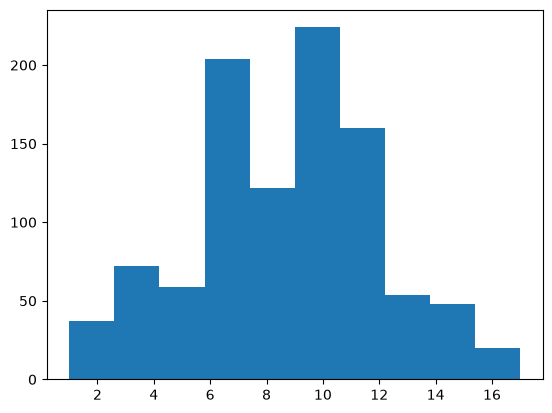

In [68]:
name_v = np.random.normal(loc=9, scale=3.5, size=1000).astype(int)
name_v = np.clip(name_v, 1, 17)
name_samples_v = np.clip(np.round(name_v), 1, 17).astype(int)
print(name_samples_v)
plt.hist(name_samples_v)
plt.show()